<style>
/* ==== Global Typography ==== */
body { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, sans-serif; }
h2 { border-bottom: 3px solid #4A90D9; padding-bottom: 6px; color: #2C3E50; margin-top: 36px; }
h3 { color: #34495E; margin-top: 20px; }

/* ==== Roadmap Table ==== */
.roadmap-table { width: 100%; border-collapse: collapse; margin: 12px 0; font-size: 0.92em; }
.roadmap-table th { background: #4A90D9; color: #fff; padding: 8px 10px; text-align: left; }
.roadmap-table td { padding: 6px 10px; border-bottom: 1px solid #E0E0E0; }
.roadmap-table tr:nth-child(even) { background: #F5F8FC; }

/* ==== Section Divider ==== */
.section-hr { height: 2px; background: linear-gradient(to right, #4A90D9, #81C784, #FFB74D); margin: 28px 0 20px 0; border-radius: 1px; }

/* ==== Hint Box ==== */
.hint-box { background: #E8F5E9; border-left: 4px solid #43A047; padding: 10px 14px; margin: 8px 0; border-radius: 0 6px 6px 0; }
.hint-box summary { cursor: pointer; font-weight: bold; color: #2E7D32; font-size: 0.95em; }
.hint-box ul { margin: 6px 0 0 0; padding-left: 20px; }
.hint-box li { margin: 2px 0; }

/* ==== Badges ==== */
.badge-core { background: #4A90D9; color: #fff; padding: 2px 8px; border-radius: 10px; font-size: 0.78em; font-weight: bold; }

/* ==== Exercise Block ==== */
.exercise-block {
    background: #FFF8E1 !important;
    border-left: 4px solid #FFC107;
    padding: 14px 18px;
    margin: 10px 0;
    border-radius: 0 8px 8px 0;
}
.exercise-block h3 { color: #1A237E; }
.exercise-block p, .exercise-block li, .exercise-block ol { color: #283593; }
.exercise-block code { color: #1565C0; background: #E3F2FD; padding: 1px 4px; border-radius: 3px; }

/* ==== Cell-level styling (Jupyter / JupyterLab) ==== */
.cell.tag_exercise { background-color: #FFF8E1 !important; }
.cell.tag_exercise .input_area { background-color: #FFF8E1 !important; }
.jp-Cell[data-tags~="exercise"] { background-color: #FFF8E1 !important; }
.jp-Cell[data-tags~="exercise"] .jp-Cell-inputWrapper { background-color: #FFF8E1 !important; }

/* ==== Key Concept Box ==== */
.key-concept { background: #E8EAF6; border-left: 4px solid #3F51B5; padding: 12px 16px; margin: 12px 0; border-radius: 0 8px 8px 0; }
.key-concept p { margin: 4px 0; }
</style>


# 人工智能与机器学习 — 实验2
## 机器学习算法入门：聚类、回归与分类

| 学号      | 姓名 | 日期      |
|----------|------|-----------|
|2024113552|陈雅芬 |2026.11.13 |

---

### 📋 学习路线图

| 阶段 | 主题 | 算法 | 数据集 | 技能 |
|:---:|------|------|--------|------|
| 0 | 环境准备 | — | — | 导入库、确认环境 |
| 1 | K-means 聚类 | 无监督学习 | 啤酒数据集 | 数据标准化、聚类、轮廓系数、最优K选择 |
| 2 | 线性回归 | 回归 | 共享单车数据集 | 训练/测试划分、一元/多元回归、模型评价 |
| 3 | 逻辑回归 | 分类 | 人类活动识别 | 标签编码、正则化、多分类、分类指标计算 |

> **使用说明**：每个阶段包含 **知识准备**（示例代码，供参考）和 **练习**（需要你动手完成）。练习区底色为浅黄色，方便识别。提示可点击展开，建议先独立尝试再看答案。练习 0-4 均为必做题，满分 100 分。

> **实验1 回顾**：在实验1中，我们使用 Python 完成了泰坦尼克号数据的清洗、分析和可视化——这是数据科学的"基本功"。本次实验将更进一步，带你用 **机器学习算法** 从数据中自动发现规律、做出预测。你将依次体验三种经典范式：**聚类**（把数据自动分组）→ **回归**（预测连续数值）→ **分类**（判断数据属于哪一类）。

<div class="section-hr"></div>


## 0. 环境准备

> 机器学习之旅即将开始——先检查你的工具箱是否齐全。

### 0.1 知识准备：Scikit-learn 简介

**Scikit-learn**（简称 sklearn）是 Python 最流行的机器学习库，它提供了一套统一的 API 接口：

- **估计器（Estimator）**：所有模型都实现了 `fit()` 方法用于训练
- **预测器（Predictor）**：训练好的模型用 `predict()` 做预测
- **转换器（Transformer）**：预处理工具用 `fit_transform()` 转换数据

```python
from sklearn.xxx import SomeModel      # 1. 导入
model = SomeModel(param1=..., param2=...)  # 2. 实例化
model.fit(X_train, y_train)            # 3. 训练
y_pred = model.predict(X_test)         # 4. 预测
```

In [12]:
# 核心库一览（后续各节会分别导入）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# sklearn 核心模块
#   sklearn.cluster       — 聚类算法
#   sklearn.linear_model  — 线性模型（回归+分类）
#   sklearn.model_selection — 数据划分、交叉验证
#   sklearn.preprocessing  — 数据预处理
#   sklearn.metrics        — 评价指标

print("✅ 环境就绪！")


✅ 环境就绪！


<div class="exercise-block">

### 0.2 练习：确认环境 <span class="badge-core">必做</span>

1. 在下方代码格中导入以下库：`pandas`、`numpy`、`matplotlib.pyplot`、`sklearn`
2. 设置 `%matplotlib inline`
3. 打印各库的版本号（`pandas.__version__` 等）
4. 检查是否能正确读取 `e2.0_beer.txt`（beer 数据集），显示前 5 行

</div>


In [13]:
# 请在此处编写代码
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn 

%matplotlib inline

print(pd.__version__)
print(np.__version__)
print(plt.matplotlib.__version__)
print(sklearn.__version__)

beer=pd.read_csv('e2.0_beer.txt',sep=' ')
beer.head()

3.0.6
2.5.1
3.11.0
1.9.1


,name,calories,sodium,alcohol,cost
0,Budweiser,144,15,4.7,0.43
1,Schlitz,151,19,4.9,0.43
2,Lowenbrau,157,15,0.9,0.48
3,Kronenbourg,170,7,5.2,0.73
4,Heineken,152,11,5.0,0.77


<div class="hint-box">
<details>
<summary>💡 点击查看提示</summary>

- 读取 txt 文件如果分隔符不是逗号，需要指定 `sep` 参数，例：`pd.read_csv('file.txt', sep=' ')`
- `pd.__version__` 返回 pandas 版本
- `.head()` 查看前5行
</details>
</div>


<div class="section-hr"></div>


> 你已经会用 Pandas 探索数据了。但如果给你一堆没有标签的数据，如何发现其中隐藏的分组？这就是 **无监督学习** 要解决的问题——从数据本身的结构中自动发现规律。


## 1. K-means 聚类 — 无监督学习入门

### 1.1 知识准备：K-means 算法原理与 API

<div class="key-concept">

**什么是聚类？** 聚类（Clustering）是将数据点按相似度自动分为若干组（簇），使得**簇内相似度高、簇间差异大**。

**K-means 的核心思想：**
1. 随机选择 K 个中心点
2. 将每个数据点分配到最近的中心点
3. 重新计算每个簇的中心点（均值）
4. 重复步骤 2-3，直到中心点不再变化

</div>

**🔹 scikit-learn 中 K-means 的用法：**

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 示例：生成一些随机数据
np.random.seed(42)
X_demo = np.vstack([
    np.random.randn(50, 2) + [2, 2],   # 簇1
    np.random.randn(50, 2) + [-2, -2], # 簇2
    np.random.randn(50, 2) + [2, -2],  # 簇3
])

# 数据标准化（重要！K-means 对尺度敏感）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_demo)

# 训练 K-means
km = KMeans(n_clusters=3, random_state=42)
km.fit(X_scaled)

# 查看结果
print("簇标签:", km.labels_[:10], "...")
print("簇中心:\n", km.cluster_centers_)


簇标签: [2 2 2 2 2 2 2 2 2 2] ...
簇中心:
 [[-1.23898584 -0.59685943]
 [ 0.74458464 -0.68452962]
 [ 0.57709384  1.23940359]]


d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


**🔹 如何选择最优 K 值？—— 轮廓系数（Silhouette Score）**

轮廓系数衡量聚类质量，取值 [-1, 1]，越大越好：

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

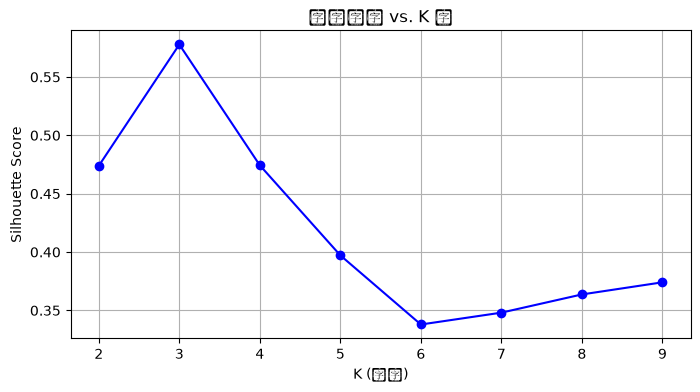

最优 K = 3, 轮廓系数 = 0.578


In [15]:
from sklearn.metrics import silhouette_score

# 遍历不同的 K 值
k_range = range(2, 10)
scores = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    scores.append(silhouette_score(X_scaled, km.labels_))

# 画图
plt.figure(figsize=(8, 4))
plt.plot(k_range, scores, 'bo-')
plt.xlabel('K (簇数)')
plt.ylabel('Silhouette Score')
plt.title('轮廓系数 vs. K 值')
plt.grid(True)
plt.show()
print(f"最优 K = {k_range[np.argmax(scores)]}, 轮廓系数 = {max(scores):.3f}")


> ✅ 小结：K-means 三步走 — **标准化 → fit → 评价（轮廓系数）**。

<div class="exercise-block">

### 1.2 练习：啤酒聚类分析 <span class="badge-core">必做</span>

啤酒数据集 `e2.0_beer.txt` 包含 20 种啤酒的 `calories`（热量）、`sodium`（钠）、`alcohol`（酒精度）、`cost`（价格）四个特征。请完成以下任务：

1. 读取数据，将 `name` 列以外的四列作为特征 `X`
2. 使用 `StandardScaler` 对 `X` 进行标准化
3. 用 K=3 训练 K-means 模型，**变量名必须为 `km`**
4. 将聚类标签添加到原数据框，按簇排序后展示
5. 计算 K=3 时的轮廓系数
6. 绘制散点图：x=calories, y=alcohol，按簇着色，用 `+` 标记簇中心
7. 遍历 K=2 到 10，画出轮廓系数 vs. K 的折线图，找出最优 K 值

</div>


d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


                    name  calories  sodium  alcohol  cost  cluster
0              Budweiser       144      15      4.7  0.43        0
1                Schlitz       151      19      4.9  0.43        0
2             Augsberger       175      24      5.5  0.40        0
3          Old_Milwaukee       145      23      4.6  0.28        0
4   Srohs_Bohemian_Style       149      27      4.7  0.42        0
5                  Coors       140      18      4.6  0.44        0
6                  Becks       150      19      4.7  0.76        0
7                  Hamms       139      19      4.4  0.43        0
8    Heilemans_Old_Style       144      24      4.9  0.43        0
9               Heineken       152      11      5.0  0.77        1
10           Coors_Light       102      15      4.1  0.46        1
11           Miller_Lite        99      10      4.3  0.43        1
12                 Kirin       149       6      5.0  0.79        1
13        Michelob_Light       135      11      4.2  0.50     

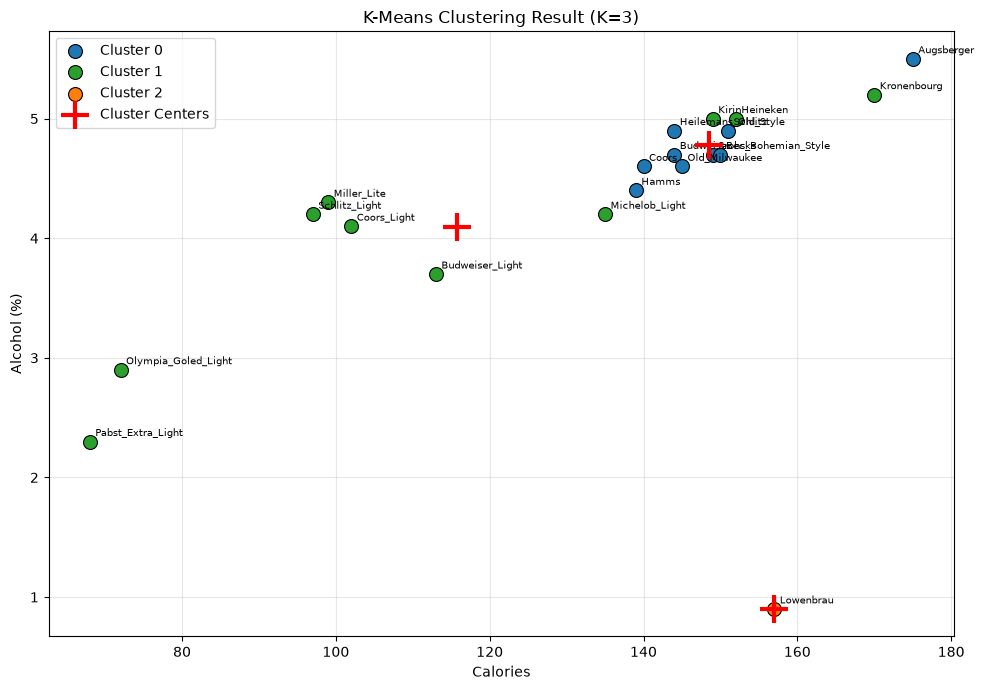

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

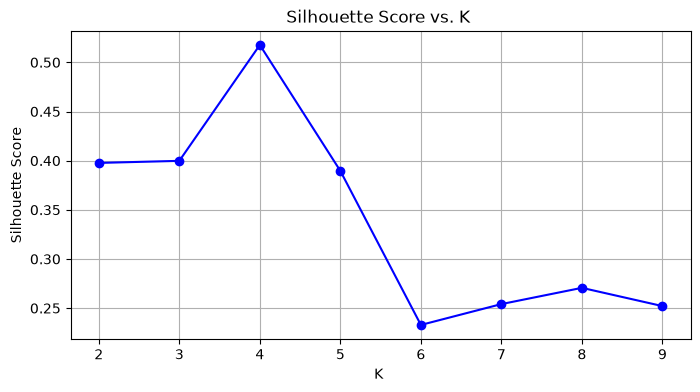

最优 K = 4, 轮廓系数 = 0.518


In [32]:
# 请在此处编写代码
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
#读取数据，
X=beer.drop('name',axis=1)

#标准化
scaler =StandardScaler()
X_scaled=scaler.fit_transform(X)

#训练k-means model
km=KMeans(n_clusters=3,random_state=42)
km.fit(X_scaled)

#按簇排序展示数据
beer['cluster']=km.labels_
beer_sorted=beer.sort_values('cluster').reset_index(drop=True)
print(beer_sorted)

silh_sc_k3=silhouette_score(X_scaled,km.labels_)
print('Silhouette Score(K=3):',silh_sc_k3)

#绘制散点图
plt.figure(figsize=(10, 7))
# 三个簇分别用三种颜色，并给出图例
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']   # 蓝、绿、橙
cluster_names = ['Cluster 0', 'Cluster 1', 'Cluster 2']
for c in range(3):
    mask = beer['cluster'] == c
    plt.scatter(beer.loc[mask, 'calories'], beer.loc[mask, 'alcohol'],
                c=colors[c], s=100, edgecolors='k', linewidths=0.8,
                label=cluster_names[c], zorder=3)
plt.scatter(centers_original[:, 0], centers_original[:, 2],
            marker='+', s=400, c='red', linewidths=3,
            label='Cluster Centers', zorder=5)
for i, row in beer.iterrows():
    plt.annotate(row['name'], (row['calories'], row['alcohol']),
                 fontsize=7, xytext=(4, 4), textcoords='offset points')
plt.xlabel('Calories')
plt.ylabel('Alcohol (%)')
plt.title('K-Means Clustering Result (K=3)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

k_range=range(2,10)
scores=[]
for K in k_range:
    km=KMeans(n_clusters=K,random_state=42)
    km.fit(X_scaled)
    scores.append(silhouette_score(X_scaled,km.labels_))
plt.figure(figsize=(8, 4))
plt.plot(k_range, scores, 'bo-')
plt.xlabel('K ')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. K ')
plt.grid(True)
plt.show()
print(f"最优 K = {k_range[np.argmax(scores)]}, 轮廓系数 = {max(scores):.3f}")


d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


轮廓系数 (K=2): 0.354
调整兰德指数 (与真实标签对比): 0.301


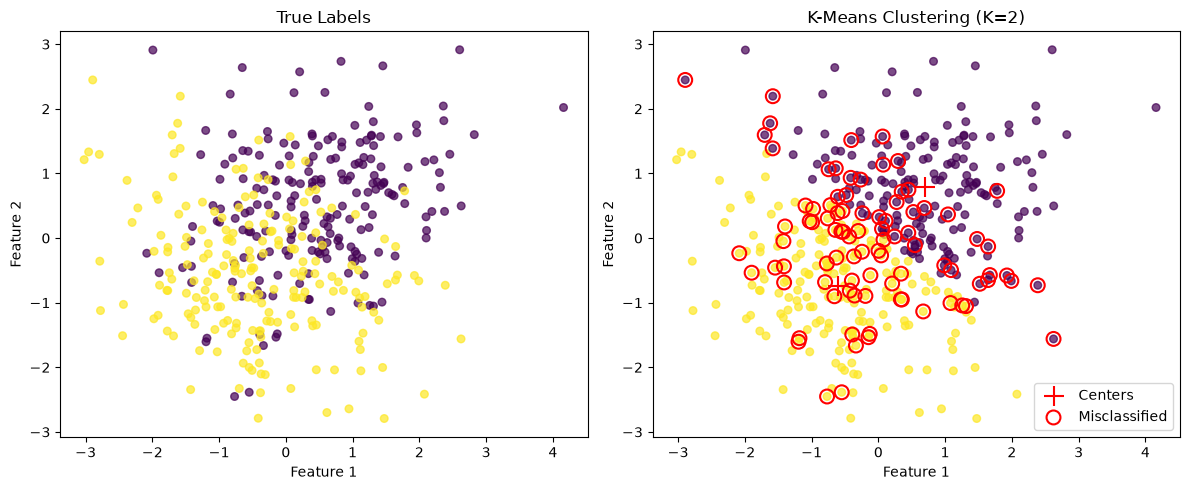

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

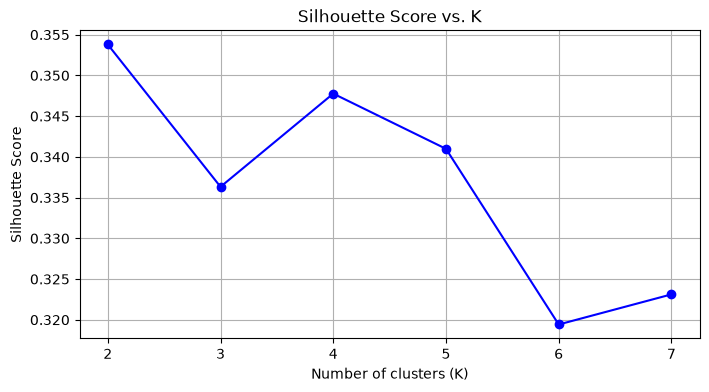

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 设置随机种子
np.random.seed(42)

# 簇1参数：均值 [0.5, 0.5]，协方差较大，产生重叠
mean1 = [0.5, 0.5]
cov1 = [[1.2, 0.3], [0.3, 1.0]]   # 非对角协方差使分布呈椭圆并倾斜
data1 = np.random.multivariate_normal(mean1, cov1, size=200)

# 簇2参数：均值 [-0.5, -0.5]，协方差类似
mean2 = [-0.5, -0.5]
cov2 = [[1.2, -0.3], [-0.3, 1.0]]
data2 = np.random.multivariate_normal(mean2, cov2, size=200)

# 合并数据
X = np.vstack([data1, data2])
true_labels = np.array([0]*200 + [1]*200)

# 标准化（K-Means 默认使用欧氏距离，标准化可均衡各特征尺度）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 训练 K-Means，K=2
km = KMeans(n_clusters=2, random_state=42)
km.fit(X_scaled)
pred_labels = km.labels_

# 评估
sil = silhouette_score(X_scaled, pred_labels)
ari = adjusted_rand_score(true_labels, pred_labels)
print(f"轮廓系数 (K=2): {sil:.3f}")
print(f"调整兰德指数 (与真实标签对比): {ari:.3f}")

# 将聚类中心反变换到原始尺度
centers_orig = scaler.inverse_transform(km.cluster_centers_)

# 可视化：左图真实标签，右图预测标签，标记误分类点
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 左图：真实标签
axes[0].scatter(X[:,0], X[:,1], c=true_labels, cmap='viridis', s=30, alpha=0.7)
axes[0].set_title('True Labels')
axes[0].set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')

# 右图：预测标签
axes[1].scatter(X[:,0], X[:,1], c=pred_labels, cmap='viridis', s=30, alpha=0.7)
axes[1].scatter(centers_orig[:,0], centers_orig[:,1], marker='+', s=200, c='red', label='Centers')
axes[1].set_title('K-Means Clustering (K=2)')
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].legend()

# 标记误分类点（在右图中用红色圆圈标出）
misclassified = true_labels != pred_labels
axes[1].scatter(X[misclassified,0], X[misclassified,1], 
                facecolors='none', edgecolors='red', s=100, linewidths=1.5, label='Misclassified')
axes[1].legend()

plt.tight_layout()
plt.show()

# 额外：观察不同K值下的轮廓系数
K_range = range(2, 8)
sil_scores = []
for k in K_range:
    km_test = KMeans(n_clusters=k, random_state=42)
    km_test.fit(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, km_test.labels_))

plt.figure(figsize=(8, 4))
plt.plot(K_range, sil_scores, 'bo-')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. K')
plt.grid(True)
plt.show()

d:\Miniconda3\envs\ML\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


聚类中心（原始尺度）：
    calories  sodium  alcohol    cost
0   148.375  21.125   4.7875  0.4075
1   105.375  10.875   3.3250  0.4475
2   155.250  10.750   4.9750  0.7625

轮廓系数 (K=3): 0.458

--- Cluster 0 ---
['Budweiser', 'Schlitz', 'Old_Milwaukee', 'Augsberger', 'Srohs_Bohemian_Style', 'Coors', 'Hamms', 'Heilemans_Old_Style']

--- Cluster 1 ---
['Lowenbrau', 'Miller_Lite', 'Budweiser_Light', 'Coors_Light', 'Michelob_Light', 'Pabst_Extra_Light', 'Olympia_Goled_Light', 'Schlitz_Light']

--- Cluster 2 ---
['Kronenbourg', 'Heineken', 'Becks', 'Kirin']


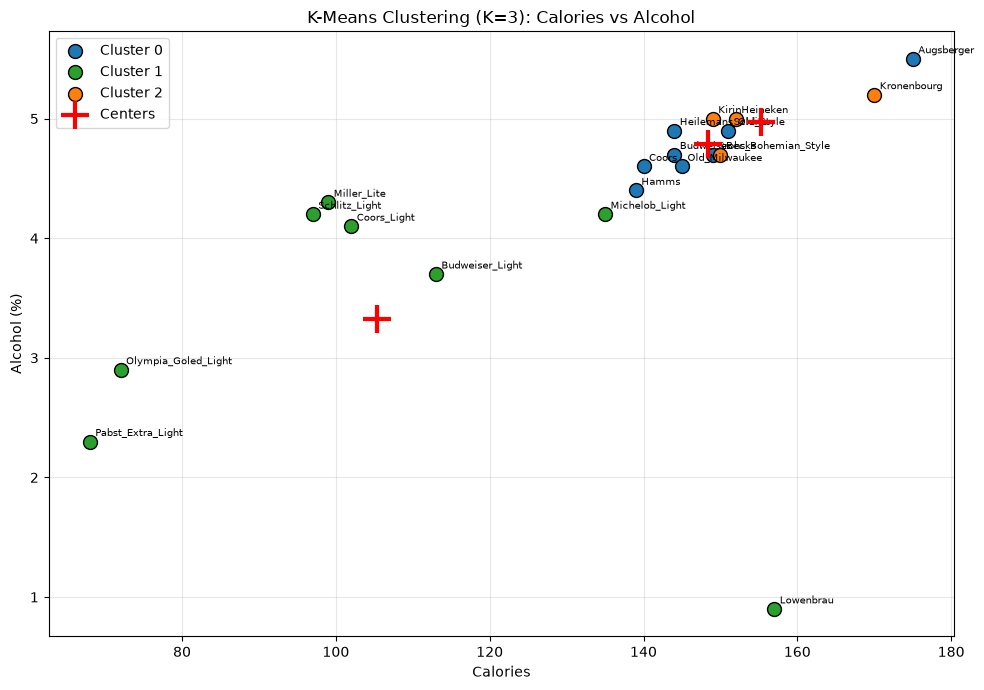

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 读取数据
df = pd.read_csv('e2.0_beer.txt', sep=' ')
features = ['calories', 'sodium', 'alcohol', 'cost']
X = df[features].values

# 标准化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# K=3 聚类
K = 3
km = KMeans(n_clusters=K, random_state=42, n_init=10)
km.fit(X_scaled)
labels = km.labels_

# 中心反变换到原始尺度
centers_orig = scaler.inverse_transform(km.cluster_centers_)
centers_df = pd.DataFrame(centers_orig, columns=features)
print("聚类中心（原始尺度）：\n", centers_df)
print("\n轮廓系数 (K=3):", round(silhouette_score(X_scaled, labels), 3))

# 打印各簇啤酒
df['cluster'] = labels
for c in range(K):
    print(f"\n--- Cluster {c} ---")
    print(df[df['cluster'] == c]['name'].tolist())

# 绘图：calories vs alcohol（最直观区分度最高的两个特征）
plt.figure(figsize=(10, 7))
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']
for c in range(K):
    mask = labels == c
    plt.scatter(X[mask, 0], X[mask, 2], c=colors[c], s=100,
                edgecolors='k', label=f'Cluster {c}', zorder=3)

plt.scatter(centers_orig[:, 0], centers_orig[:, 2],
            marker='+', s=400, c='red', linewidths=3, label='Centers', zorder=4)

# 标注啤酒名
for i, name in enumerate(df['name']):
    plt.annotate(name, (X[i, 0], X[i, 2]), fontsize=7,
                 xytext=(4, 4), textcoords='offset points')

plt.xlabel('Calories')
plt.ylabel('Alcohol (%)')
plt.title('K-Means Clustering (K=3): Calories vs Alcohol')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<div class="hint-box">
<details>
<summary>💡 点击查看提示</summary>

- 提取特征列：`X = beer.drop('name', axis=1)`
- 标准化：`scaler = StandardScaler(); X_scaled = scaler.fit_transform(X)`
- KMeans：`km = KMeans(n_clusters=3, random_state=42); km.fit(X_scaled)`
- 轮廓系数：`silhouette_score(X_scaled, km.labels_)`
- 散点图着色：`plt.scatter(..., c=colors[beer.cluster])`
- 簇中心：`km.cluster_centers_`（注意是标准化后的坐标）
</details>
</div>


<div class="section-hr"></div>


> 聚类让我们在无标签的数据中发现了分组。但如果你想预测一个**具体的数值**——比如明天的单车租赁量会是多少？——那就需要**回归**算法了。从 K-means 的无监督世界，我们进入有监督学习的领域。


## 2. 线性回归 — 预测连续值

### 2.1 知识准备：线性回归与模型评价

<div class="key-concept">

**什么是回归？** 回归（Regression）的目标是根据输入特征预测一个**连续的数值**输出。
线性回归假设输出是输入特征的线性组合：

**ŷ = w₁x₁ + w₂x₂ + ... + wₙxₙ + b**

模型通过最小化预测值与真实值之间的**均方误差（MSE）**来学习这些权重。

</div>

**🔹 scikit-learn 中的线性回归：**

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 创建模拟数据: y = 3 * x + 5 + 噪声
np.random.seed(0)
X_demo = np.random.rand(100, 1) * 10
y_demo = 3 * X_demo.ravel() + 5 + np.random.randn(100) * 2

# 划分训练/测试集（关键步骤！）
X_train, X_test, y_train, y_test = train_test_split(
    X_demo, y_demo, test_size=0.3, random_state=42
)

# 训练模型
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

# 输出结果
print(f"系数 (w): {lr.coef_[0]:.3f}")
print(f"截距 (b): {lr.intercept_:.3f}")
print(f"R² 得分: {r2_score(y_test, y_pred):.3f}")
print(f"MSE:     {mean_squared_error(y_test, y_pred):.3f}")
print(f"RMSE:    {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")


系数 (w): 3.010
截距 (b): 5.351
R² 得分: 0.947
MSE:     3.121
RMSE:    1.767


**🔹 三个核心评价指标：**

| 指标 | 含义 | 越小越好/越大越好 |
|------|------|:---:|
| **R²** (决定系数) | 模型解释了多少方差，1.0 为完美 | 越大越好 |
| **MSE** (均方误差) | 预测误差的平方均值 | 越小越好 |
| **RMSE** (均方根误差) | MSE 的平方根，与原数据同单位 | 越小越好 |

**🔹 多元线性回归**：同时使用多个特征进行预测，sklearn 用法完全相同——只需在 `X` 中包含多列。

In [18]:
# 多元回归示例：用多个特征预测
feature_cols = ['temp', 'humidity', 'windspeed']
X_multi = bikes[feature_cols]
y_multi = bikes['count']

X_train, X_test, y_train, y_test = train_test_split(
    X_multi, y_multi, test_size=0.3, random_state=42
)

lr_multi = LinearRegression().fit(X_train, y_train)
y_pred_multi = lr_multi.predict(X_test)

print("多元回归 R²:", r2_score(y_test, y_pred_multi).round(4))
# 查看每个特征的权重
for name, coef in zip(feature_cols, lr_multi.coef_):
    print(f"  {name}: {coef:.2f}")


NameError: name 'bikes' is not defined

> ✅ 线性回归的流程：**划分数据 → fit → predict → 评价（R²、MSE、RMSE）**。

<div class="exercise-block">

### 2.2 练习：共享单车租赁量预测 <span class="badge-core">必做</span>

共享单车数据集 `e2.2_bikeshare.csv` 记录了 2011–2012 年每小时的单车租赁数及天气信息。我们用温度等特征来预测租赁量 `count`。

1. 读取数据，设置 `datetime` 列为索引并解析日期（`parse_dates=True`）
2. **一元线性回归**：以 `temp`（温度）为特征，`count` 为目标
   - 划分训练/测试集（`test_size=0.3, random_state=42`）
   - 训练 `LinearRegression` 模型
   - 输出系数、截距，计算测试集上的 R²、RMSE
   - 绘制散点图（x=temp, y=count）+ 回归直线
3. **多元线性回归**：额外加入 `season`、`humidity`、`windspeed`
   - 用这四个特征重新训练模型
   - 计算测试集 R²、RMSE
   - 对比一元与多元模型的性能，哪个更好？为什么？

</div>


In [ ]:
# 请在此处编写代码


<div class="hint-box">
<details>
<summary>💡 点击查看提示</summary>

- 读取 CSV 指定索引列：`pd.read_csv('e2.2_bikeshare.csv', index_col='datetime', parse_dates=True)`
- 划分数据：`train_test_split(X, y, test_size=0.3, random_state=42)`
- 提取单列特征时注意形状：`X = bikes[['temp']]`（双括号保留 DataFrame）
- 画回归线：用 `np.linspace` 生成 x 值，`lr.predict` 得到 y 值
- 对比分析用文字写在 markdown 中即可
</details>
</div>


<div class="analysis-q">
<p><b>📝 对比分析</b>：多元回归的 R² 比一元回归更高、RMSE 更低，说明引入季节、湿度、风速等额外特征能更好地解释单车租赁量的变化。温度单独只能解释约 15-16% 的方差，而四个特征联合解释力更强。</p>
</div>

<div class="section-hr"></div>


> 回归模型能预测具体的数值。但如果你的问题是「这个人走路的姿态属于哪一种活动」呢？输出不再是数字，而是**类别标签**——这时我们需要**分类**算法。逻辑回归虽然名字里有「回归」，但它是最经典、最常用的分类模型之一，也是本次实验的重点。


## 3. 逻辑回归 — 分类与模型评价

### 3.1 知识准备：从回归到分类

<div class="key-concept">

**逻辑回归的核心思想：**
逻辑回归在线性组合的基础上加了一个 **Sigmoid 函数**，将任意实数映射到 (0, 1) 区间，表示为"属于某类"的概率：

**P(y=1) = 1 / (1 + e<sup>-(wx + b)</sup>)**

对于多分类问题，sklearn 默认使用 **OvR（One-vs-Rest）** 策略：为每个类别训练一个"是该类 vs 不是该类"的二分类器。

</div>

**🔹 逻辑回归的 API：**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ===== 基本用法 =====
# LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=1000)

# ===== 标签编码（把文字类别变成整数） =====
le = LabelEncoder()
y_encoded = le.fit_transform(y_labels)   # ['WALKING', 'STANDING', ...] → [0, 1, ...]

# ===== 训练模型 =====
lr_clf = LogisticRegression(max_iter=1000)
lr_clf.fit(X_train, y_train)
y_pred = lr_clf.predict(X_test)
y_proba = lr_clf.predict_proba(X_test)   # 每个类别的概率


**🔹 正则化：防止过拟合**

| 参数 | 含义 | 效果 |
|------|------|------|
| `penalty='l2'` | L2 正则化（Ridge） | 限制权重平方和，让所有权重都较小 |
| `penalty='l1'` | L1 正则化（Lasso） | 倾向于产生稀疏权重（部分为0），自带特征选择 |
| `C` | 正则化强度的倒数 | C 越大 → 正则化越弱；C 越小 → 正则化越强 |

In [ ]:
# L1 vs L2 正则化示例
lr_l2 = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs', max_iter=1000)
lr_l1 = LogisticRegression(penalty='l1', C=1.0, solver='saga', max_iter=1000)
# 注意: L1 需要 solver='saga' 或 'liblinear'


**🔹 分类模型的评价指标（重点）**

对于分类问题，仅看准确率（Accuracy）往往不够——尤其是在类别不平衡时。
以下是 **二分类** 的核心指标（多分类时可按宏平均/微平均扩展）：

In [ ]:
from sklearn.metrics import (
    accuracy_score,    # 准确率
    precision_score,   # 精确率
    recall_score,      # 召回率
    f1_score,          # F1 分数
    confusion_matrix,  # 混淆矩阵
    classification_report  # 综合报告
)

# 计算各指标
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro'):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, average='macro'):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, average='macro'):.3f}")

# 混淆矩阵
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# 综合分类报告（推荐！）
print("\n" + classification_report(y_test, y_pred,
      target_names=le.classes_))


| 指标 | 公式 | 关注点 |
|------|------|--------|
| **Accuracy** (准确率) | (TP+TN)/总数 | 整体正确率 |
| **Precision** (精确率) | TP/(TP+FP) | 预测为"正"中有多少是对的 |
| **Recall** (召回率) | TP/(TP+FN) | 真实"正"中被找出了多少 |
| **F1-score** | 2PR/(P+R) | 精确率和召回率的调和平均 |
| **Confusion Matrix** | — | 每一类的预测分布详情 |

> ✅ 分类建模流程：**编码标签 → 划分数据 → 训练模型 → 预测 → 多指标评价**。Accuracy 只是起点，Precision/Recall/F1 + 混淆矩阵才能全面诊断模型。

<div class="exercise-block">

### 3.2 练习：人类活动识别 — 逻辑回归分类 <span class="badge-core">必做</span>

人类活动识别数据集（`e2.3_Human_Activity_Recognition_Using_Smartphones_Data.csv`）包含智能手机传感器采集的 7352 条记录、561 个特征，目标是将活动分为 6 类：WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING。

**第一部分：数据准备与基础模型**

1. 读取数据，查看 `Activity` 列的值分布（`value_counts()`）
2. 用 `LabelEncoder` 将 `Activity` 列编码为 0-5 的整数
3. 划分特征 `X`（所有列去掉 `Activity` 和 `subject`，如果存在）和目标 `y`
4. 用 `train_test_split`（`test_size=0.3, random_state=42, stratify=y`）划分训练/测试集
5. 训练一个**默认参数**的 `LogisticRegression`（`max_iter=2000`），输出训练好的 Accuracy

</div>


In [ ]:
# 请在此处编写代码


<div class="hint-box">
<details>
<summary>💡 点击查看提示</summary>

- 查看类别分布：`data['Activity'].value_counts()`
- 标签编码：`le = LabelEncoder(); data['Activity'] = le.fit_transform(data['Activity'])`
- 分层抽样：`train_test_split(..., stratify=y)` 保持类别比例
- 默认逻辑回归：`LogisticRegression(max_iter=2000)`
- 计算准确率：`accuracy_score(y_test, y_pred)`
</details>
</div>


<div class="exercise-block">

### 3.3 练习：模型选择、正则化与分类指标 <span class="badge-core">必做</span>

**第二部分：模型选择与评价**

1. **正则化比较**：训练 L1 正则化（`penalty='l1', solver='saga', C=0.1`）和 L2 正则化（`penalty='l2', C=0.1`）的逻辑回归模型，两个模型均设 `max_iter=2000`
2. 对每个模型（默认 + L1 + L2），计算并打印以下指标：
   - **Accuracy**（准确率）
   - **Precision**（精确率，`average='macro'`）
   - **Recall**（召回率，`average='macro'`）
   - **F1-score**（`average='macro'`）
3. 对表现最好的模型，打印 **分类报告**（`classification_report`）和 **混淆矩阵**
4. 分析 L1/L2 正则化对模型的影响：哪个更好？为什么 L1 在特征很多时特别有用？

</div>


In [ ]:
# 请在此处编写代码


<div class="hint-box">
<details>
<summary>💡 点击查看提示</summary>

- L1 逻辑回归：`LogisticRegression(penalty='l1', solver='saga', C=0.1, max_iter=2000)`
- 函数导入：`from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report`
- 宏平均（macro）：先对每个类别分别计算指标，再取平均
- 分类报告：`print(classification_report(y_test, y_pred, target_names=le.classes_))`
- 混淆矩阵可视化：可以用 `plt.imshow()` 绘制热力图
</details>
</div>


<div class="analysis-q">
<p><b>📝 L1 vs L2 正则化分析</b>：</p>
<ul>
<li><b>L2 正则化</b>让所有权重趋近于零但不为零，在特征都相关时表现稳定。</li>
<li><b>L1 正则化</b>倾向于将不重要的特征权重压缩到零，自动实现特征选择——这在特征数量很大（本例561个）时特别有用，能降低模型复杂度、提高可解释性。</li>
<li>在本数据集中，由于所有传感器特征都经过精心设计，L1 和 L2 的准确率通常接近，但 L1 的系数矩阵更稀疏。</li>
</ul>
</div>

<div class="section-hr"></div>


## 🎓 实验总结

恭喜你完成了人工智能实训的第二个实验！让我们回顾一下你掌握的技能：

| 算法 | 类型 | 核心任务 | 关键技能 |
|------|:---:|------|------|
| **K-means** | 无监督学习 | 啤酒聚类 | 数据标准化、轮廓系数、最优K选择 |
| **线性回归** | 回归 | 单车租赁量预测 | 训练/测试划分、多元回归、R²/RMSE评价 |
| **逻辑回归** | 分类 | 人类活动识别 | 标签编码、正则化(L1/L2)、多分类、分类指标 |

<div class="key-concept">
<p><b>🔑 机器学习建模的核心流程：</b></p>
<p><b>数据准备</b>（读取、编码、标准化） → <b>划分</b>（train/test split） → <b>训练</b>（fit） → <b>预测</b>（predict） → <b>评价</b>（多指标综合判断） → <b>改进</b>（调参、正则化、特征选择）</p>
</div>

> **下一步**：在后续实验中，你将学习深度学习等更强大的非线性模型，以及如何用交叉验证系统化地选择最优模型。